<a href="https://colab.research.google.com/github/torcodex/Wall-Mart-Forecast/blob/main/WallMart_Forecsat.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from prophet import Prophet
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant
from prophet import Prophet
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

In [83]:
df = pd.read_csv('/content/Walmart (1) - Walmart (1).csv')
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [85]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')

In [86]:
df.sort_values(by='Date', inplace=True)
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1287,10,2010-02-05,2193048.75,0,54.34,2.962,126.442065,9.765
5148,37,2010-02-05,536006.73,0,45.97,2.572,209.852966,8.554
2288,17,2010-02-05,789036.02,0,23.11,2.666,126.442065,6.548
4147,30,2010-02-05,465108.52,0,39.05,2.572,210.752605,8.324
...,...,...,...,...,...,...,...,...
3574,25,2012-10-26,688940.94,0,56.69,3.882,216.151590,7.293
714,5,2012-10-26,319550.77,0,71.70,3.506,224.037814,5.422
5719,40,2012-10-26,921264.52,0,49.65,3.917,138.728161,4.145
2573,18,2012-10-26,1127516.25,0,56.09,3.917,138.728161,8.243


In [87]:
df.duplicated().sum()

np.int64(0)

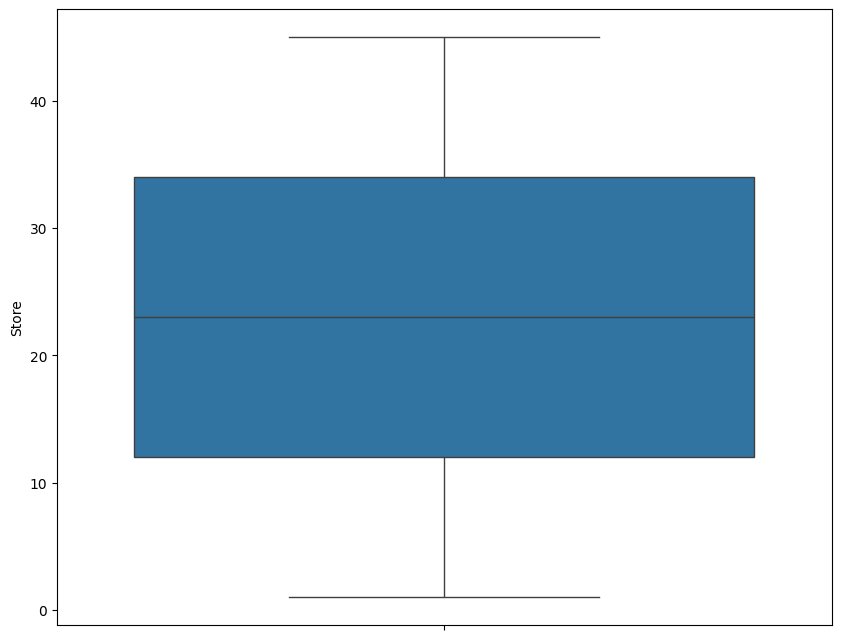

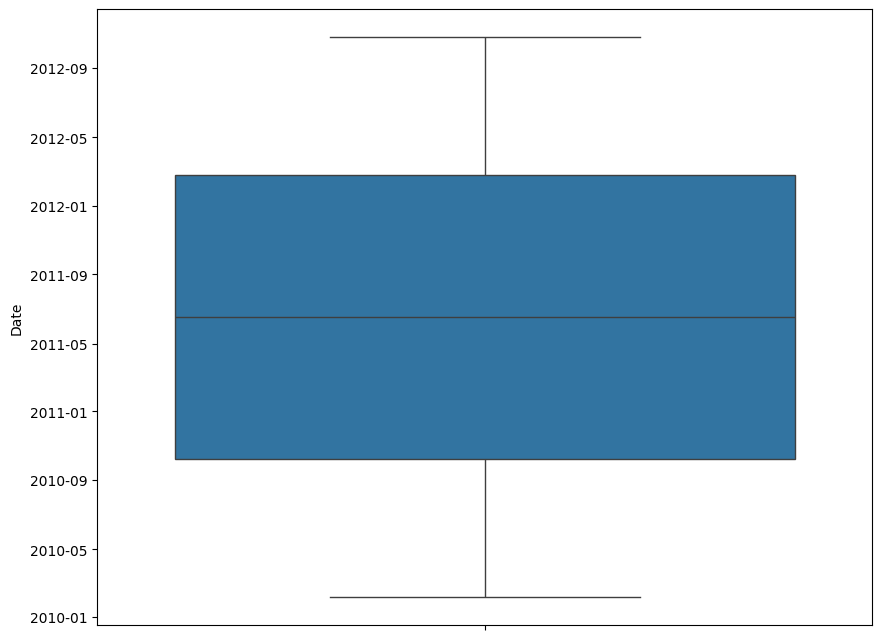

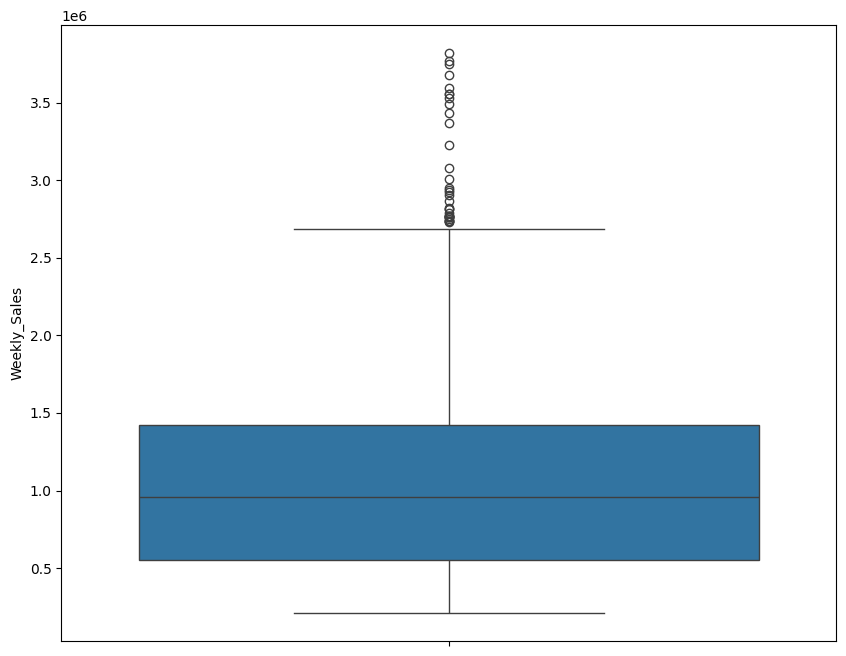

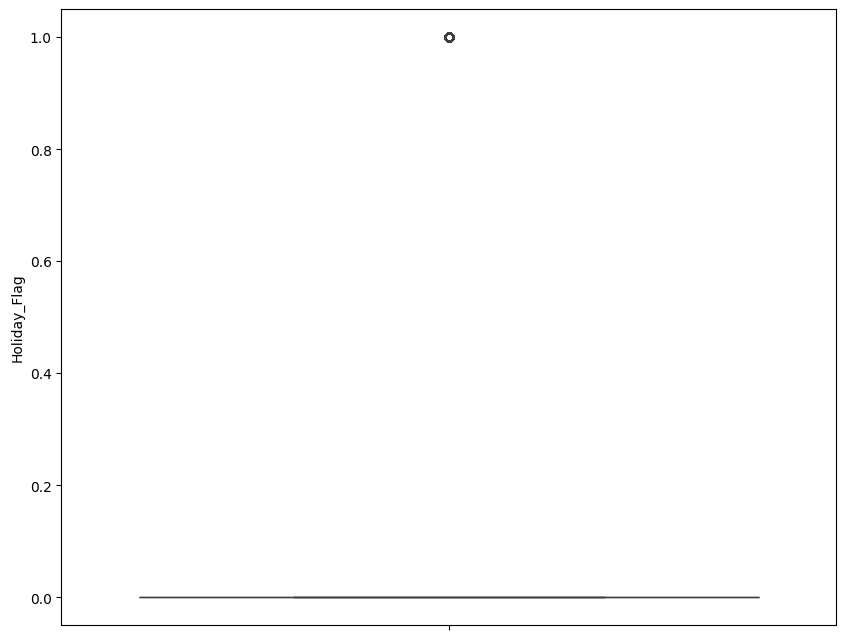

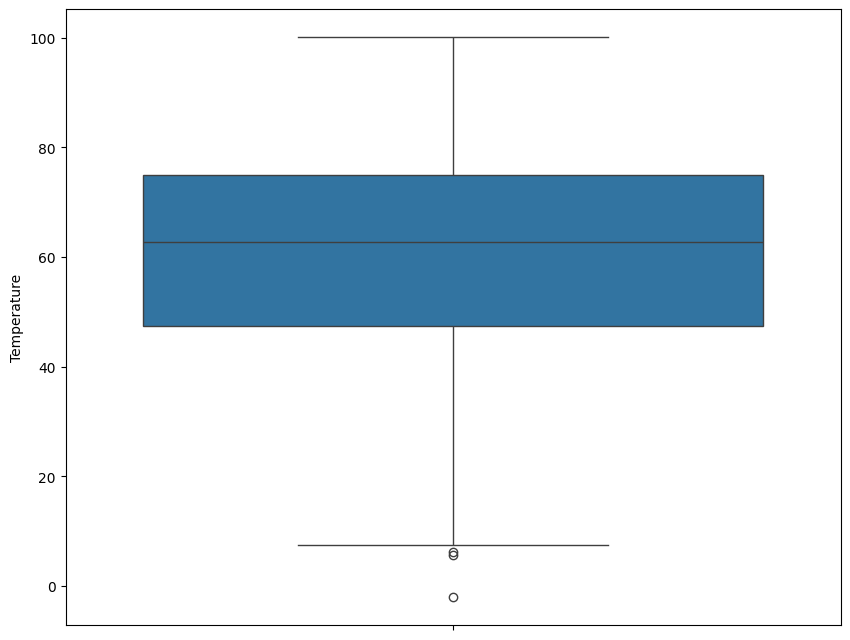

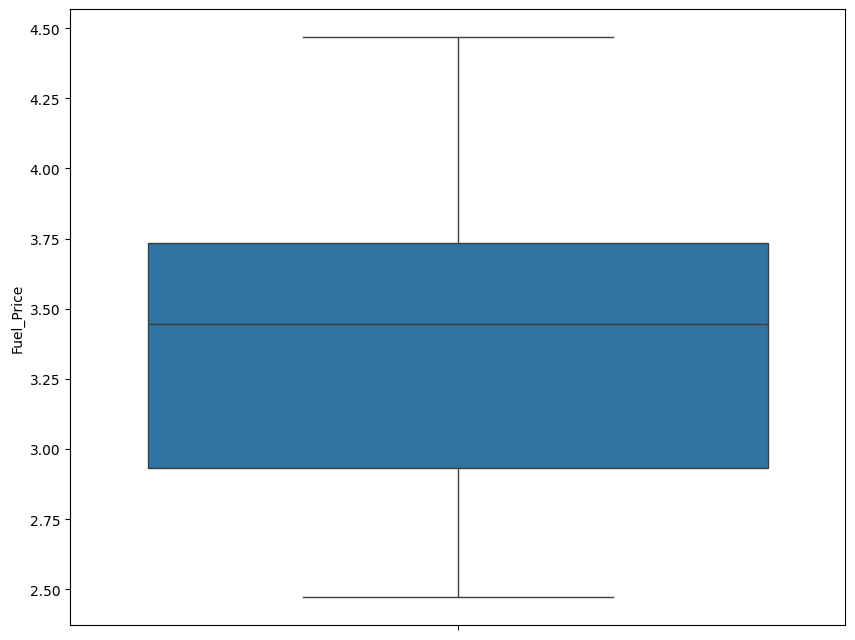

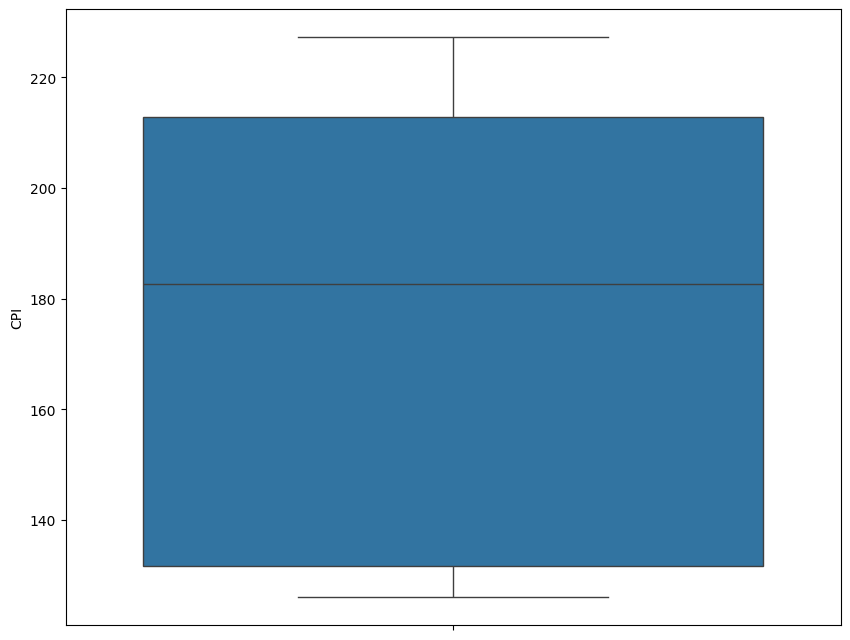

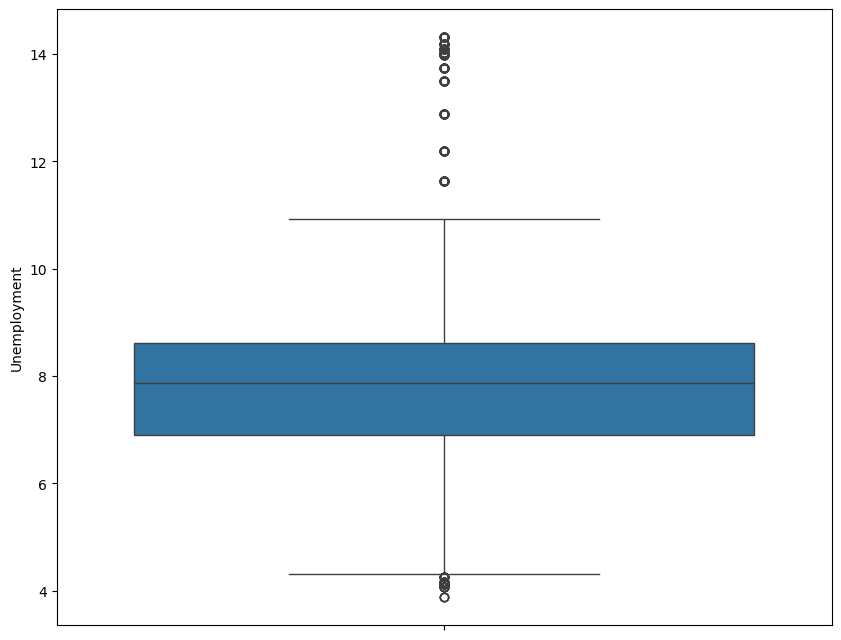

In [88]:
for i in df.columns:
    plt.figure(figsize=(10,8))
    sns.boxplot(df[i])
    plt.show()

In [89]:
out_cols = ['Weekly_Sales','Unemployment']

for i in out_cols:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3-q1
    upper = q3+1.5*iqr
    lower = q1-1.5*iqr
    df[i] = np.where(df[i]>upper,upper,np.where(df[i]<lower,lower,df[i]))

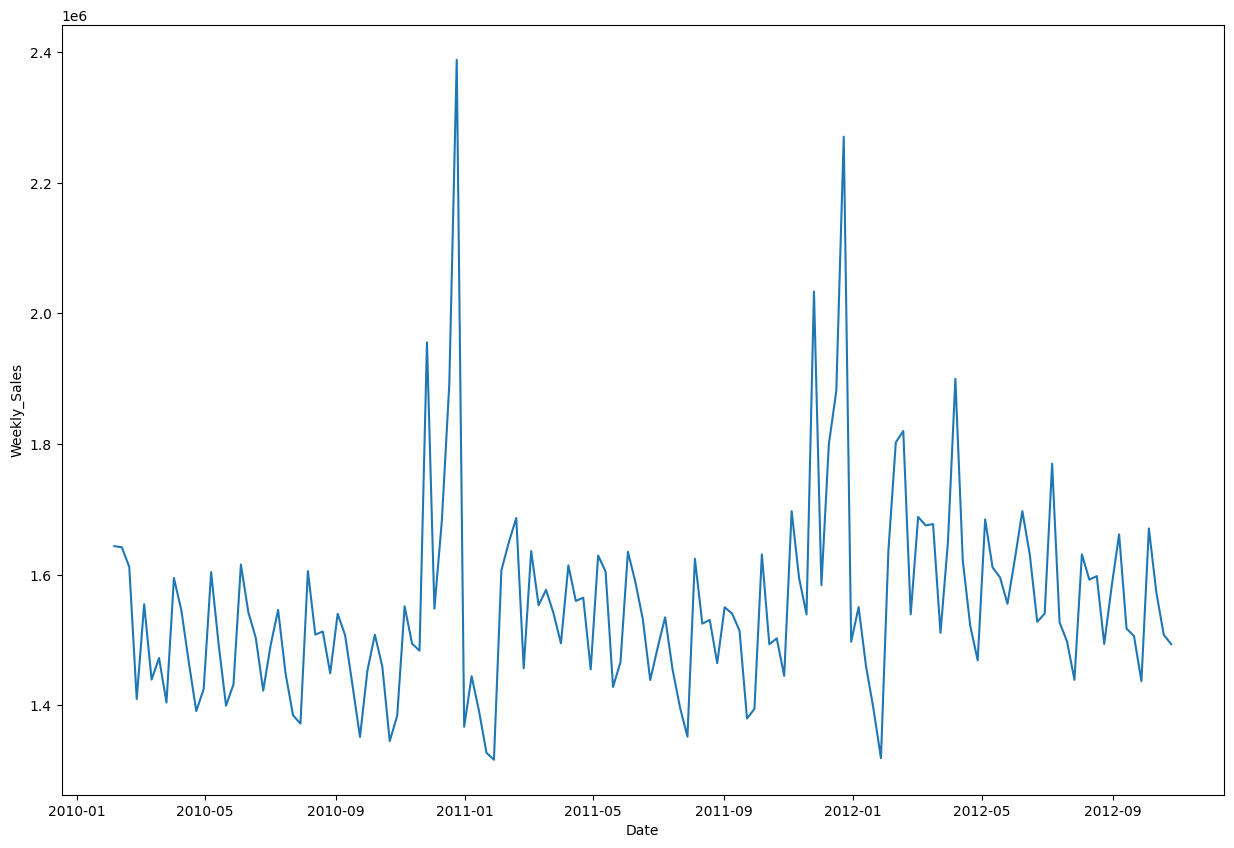

In [90]:
store1 = df[df['Store']==1]

plt.figure(figsize=(15,10))
sns.lineplot(x='Date',y='Weekly_Sales',data=store1)
plt.show()

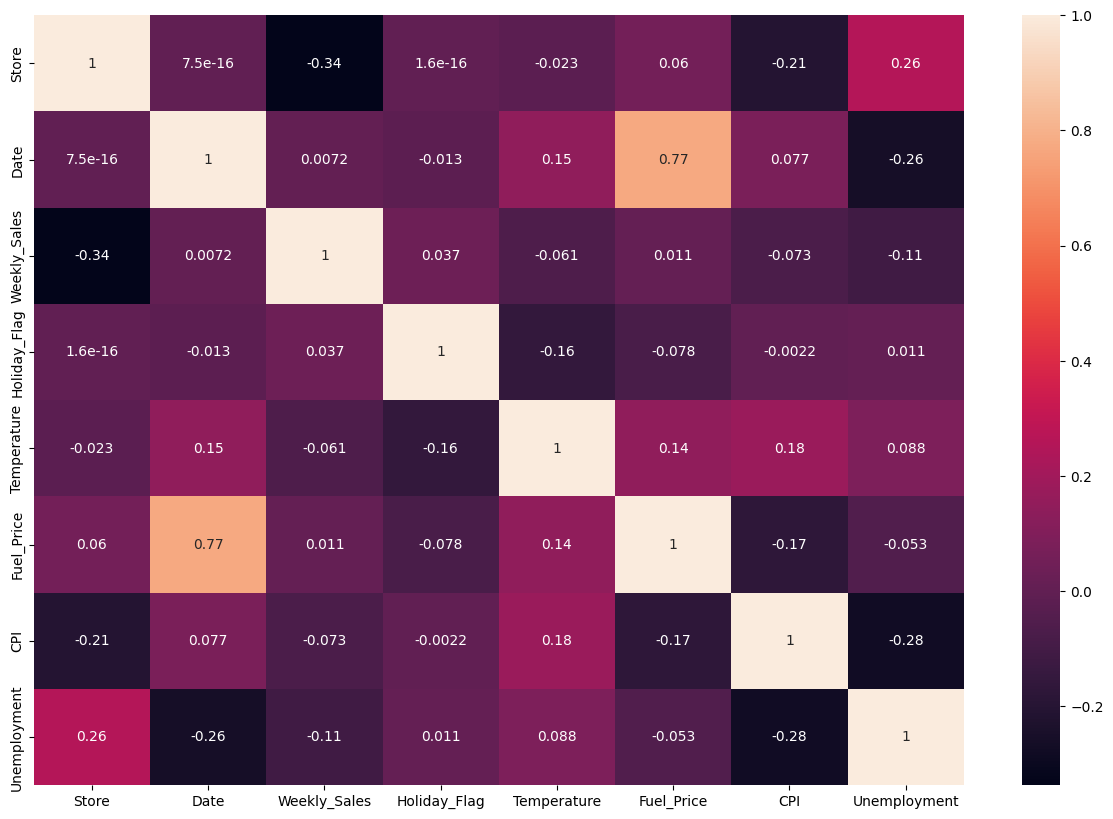

In [91]:
plt.figure(figsize=(15,10))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [92]:
# df.drop(columns={'Temperature','Fuel_Price'}, axis=1, inplace=True)

In [98]:
# Exclude non-numeric columns like 'Date'
x = df.drop(columns=['Weekly_Sales','Date'], axis=1)
y = df['Weekly_Sales']

X = add_constant(x)
vif_data = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [
        variance_inflation_factor(X.values, i)
        for i in range(X.shape[1])
    ]
})
vif_data

,Feature,VIF
0,const,1.000000
1,Store,1.097775
2,Holiday_Flag,1.029030
3,Temperature,1.123732
4,Fuel_Price,1.090647
5,CPI,1.219649
6,Unemployment,1.184617


In [101]:
df_prophet = df.groupby('Date')['Weekly_Sales'].sum().reset_index()
df_prophet.rename(columns={'Date':'ds','Weekly_Sales':'y'},inplace=True)
df_prophet

,ds,y
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30
...,...,...
138,2012-09-28,43734899.40
139,2012-10-05,47566639.31
140,2012-10-12,46128514.25
141,2012-10-19,45122410.57


In [104]:
df_prophet.duplicated().sum()

np.int64(0)

In [105]:
train = df_prophet.iloc[:-12]
test = df_prophet.iloc[-12:]

In [107]:
m = Prophet(weekly_seasonality=True,yearly_seasonality=True,daily_seasonality=False)
m.fit(train)

In [108]:
future = m.make_future_dataframe(periods=12, freq='W-FRI')
future.tail(12)

,ds
131,2012-08-10
132,2012-08-17
133,2012-08-24
134,2012-08-31
135,2012-09-07
136,2012-09-14
137,2012-09-21
138,2012-09-28
139,2012-10-05
140,2012-10-12


In [109]:
forecast = m.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

,ds,yhat,yhat_lower,yhat_upper
138,2012-09-28,4.396579e+07,3.998610e+07,4.825079e+07
139,2012-10-05,4.527341e+07,4.116772e+07,4.942190e+07
140,2012-10-12,4.571813e+07,4.160656e+07,5.019654e+07
141,2012-10-19,4.516264e+07,4.090054e+07,4.920988e+07
142,2012-10-26,4.498350e+07,4.031412e+07,4.904987e+07


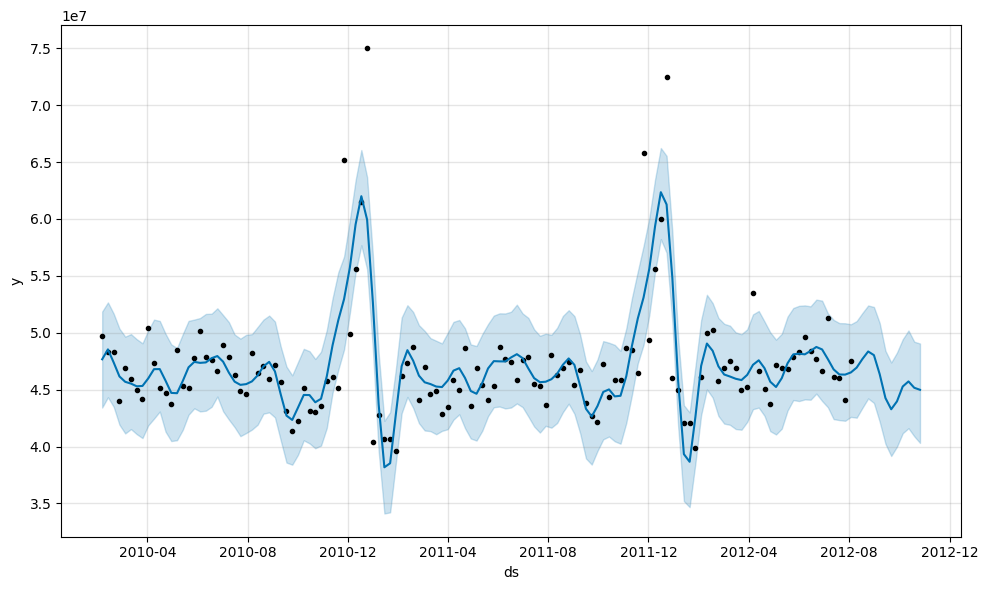

In [110]:
fig1 = m.plot(forecast)

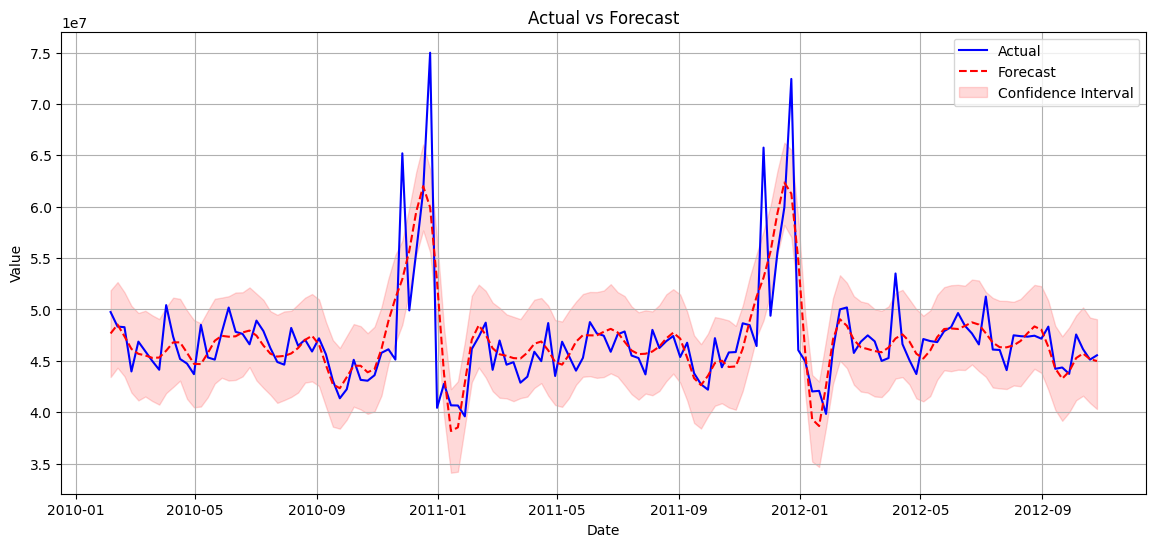

In [112]:
# Create comparison DataFrame using df_prophet which contains 'ds' and 'y'
comparison = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].merge(
    df_prophet[['ds', 'y']],
    on='ds',
    how='left'
)

plt.figure(figsize=(14, 6))

plt.plot(comparison['ds'], comparison['y'],
         label='Actual', color='blue')

plt.plot(comparison['ds'], comparison['yhat'],
         label='Forecast', color='red', linestyle='--')

plt.fill_between(
    comparison['ds'],
    comparison['yhat_lower'],
    comparison['yhat_upper'],
    color='red',
    alpha=0.15,
    label='Confidence Interval'
)

plt.xlabel('Date')
plt.ylabel('Value')
plt.title('Actual vs Forecast')
plt.legend()
plt.grid(True)
plt.show()

In [114]:
# Generate predictions specifically for the test set dates
forecast_test = m.predict(test[['ds']])

# Extract the forecasted metrics
predictions = forecast_test[['ds', 'yhat', 'yhat_lower', 'yhat_upper']]

# Merge test data with the predictions
comparison = test.merge(predictions, on='ds', how='left')
comparison

,ds,y,yhat,yhat_lower,yhat_upper
0,2012-08-10,47403451.04,4.693292e+07,4.267423e+07,5.102167e+07
1,2012-08-17,47354452.05,4.768861e+07,4.376076e+07,5.205926e+07
2,2012-08-24,47447323.60,4.835073e+07,4.412814e+07,5.246099e+07
3,2012-08-31,47159639.43,4.802812e+07,4.353910e+07,5.205722e+07
4,2012-09-07,48330059.31,4.635660e+07,4.246088e+07,5.045586e+07
5,2012-09-14,44226038.65,4.425844e+07,4.010969e+07,4.850591e+07
6,2012-09-21,44354547.11,4.327291e+07,3.915436e+07,4.754551e+07
7,2012-09-28,43734899.40,4.396579e+07,3.970938e+07,4.822772e+07
8,2012-10-05,47566639.31,4.527341e+07,4.108325e+07,4.953558e+07
9,2012-10-12,46128514.25,4.571813e+07,4.174886e+07,4.957014e+07


In [118]:
# Calculate metrics using the correct 'comparison' DataFrame
mse = mean_squared_error(comparison['y'], comparison['yhat'])
mae = mean_absolute_error(comparison['y'], comparison['yhat'])
rmse = root_mean_squared_error(comparison['y'], comparison['yhat'])

print(f'MSE: {mse}')
print(f'MAE: {mae}')
print(f'RMSE: {rmse}')

MSE: 1063795746619.0858
MAE: 766617.9596046997
RMSE: 1031404.7443264384


In [119]:
# Calculate Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((comparison['y'] - comparison['yhat']) / comparison['y'])) * 100
accuracy = 100 - mape

print(f"Mean Absolute Percentage Error (MAPE): {mape:.2f}%")
print(f"Model Accuracy (100 - MAPE): {accuracy:.2f}%")

Mean Absolute Percentage Error (MAPE): 1.63%
Model Accuracy (100 - MAPE): 98.37%
